In [ ]:
# =============================================================================
# IMPORTS AND DATA CONFIGURATION
# =============================================================================

# Set up the libraries required for loading, analysing, and visualising
# precomputed radiosonde momentum flux data.
import iris
import numpy as np
import sys
import subprocess
import matplotlib.pyplot as plt
import scipy
from pathlib import Path
from scipy.signal import savgol_filter
from scipy.interpolate import RegularGridInterpolator
from iris.analysis import trajectory
from iris.analysis.cartography import rotate_pole
from matplotlib.colors import TwoSlopeNorm

from datetime import datetime

# Add the TEAMx repository to Python's module search path.
# This allows custom analysis modules to be imported in subsequent cells.
sys.path.append("/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/")


# =============================================================================
# LOAD FILE LISTS FOR THE THREE MOMENTUM FLUX DATASETS
# =============================================================================

# Base directory containing the precomputed momentum flux arrays for IOP 17/18.
data_path_base = "/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18"

# Define directories for the three datasets:
#   Raw:    Fluxes calculated from the original radiosonde observations.
#   Model:  Fluxes calculated from model data sampled along sonde trajectory.
#   Coarse: Fluxes calculated from sonde data coarsened to model levels.
raw_flux_dir = f"{data_path_base}/iop_17_18_raw_sonde_flux_arrays"
model_flux_dir = f"{data_path_base}/iop_17_18_model_sonde_flux_arrays"
coarse_flux_dir = f"{data_path_base}/iop_17_18_coarse_sonde_flux_arrays"

# Retrieve the saved .npz files for each dataset.
# Sorting provides a consistent filename order for subsequent processing.
#
# Later comparisons by list index assume that the corresponding files
# in all three directories represent the same radiosonde.
raw_fluxes = sorted(Path(raw_flux_dir).glob("*.npz"))
model_fluxes = sorted(Path(model_flux_dir).glob("*.npz"))
coarse_fluxes = sorted(Path(coarse_flux_dir).glob("*.npz"))


# Display the available coarsened flux files to verify that the expected
# dataset has been located before proceeding with the analysis.
coarse_fluxes

[PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/iop_17_18_coarse_sonde_flux_arrays/202502250800_S0240170_STERZING_NCAS_u-eb392_run1_0p3km_ModelLevel_v0.4.Met_0_Momentum_Flux_model_sonde.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/iop_17_18_coarse_sonde_flux_arrays/202502250800_S0240175_STERZING_NCAS_u-eb392_run1_0p3km_ModelLevel_v0.4.Met_1_Momentum_Flux_model_sonde.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/iop_17_18_coarse_sonde_flux_arrays/202502251100_S0230653_STERZING_NCAS_u-eb392_run1_0p3km_ModelLevel_v0.4.Met_2_Momentum_Flux_model_sonde.npz'),
 PosixPath('/home/users/jmtd42/TEAMx/TEAMxRadiosondes_Public/src/amrit_exploration/momentum_fluxes/iop_17_18/iop_17_18_coarse_sonde_flux_arrays/202502251100_S0240214_STERZING_NCAS_u-eb392_run1_0p3km_ModelLevel_v0.4.Met_3_Momentum_Flux_mod

In [ ]:
# =============================================================================
# CONSTRUCT A COMMON TIME AXIS FOR THE RADIOSONDE OBSERVATIONS
# =============================================================================

# Extract the launch times associated with each radiosonde flux file.
# These timestamps establish the temporal distribution of the observations
# and will be used to relate momentum flux variability to launch time.
dates_list = []
for i in raw_fluxes:
    name = i.stem
    date = name[0:12]
    date = datetime.strptime(date, "%Y%m%d%H%M")
    dates_list.append(date)

dates_array = np.array(dates_list)

# Determine the time separation between consecutive radiosondes.
# hours_diff contains the launch intervals in hours, providing a measure
# of how regularly the observations sample the IOP.
time_diffs = np.diff(dates_array)

hours_diff = np.zeros_like(time_diffs)

for i in range(0, len(time_diffs)):
    hours_diff[i] = round(time_diffs[i].total_seconds()/3600,2)

# Express each launch time relative to the first radiosonde.
# time_passed therefore represents the progression through the IOP
# in days, rather than using absolute dates.
#
# Each entry corresponds to the radiosonde at the same index in raw_fluxes.
time_passed = np.zeros_like(dates_array)

# Take the difference, in days, from first sonde:
for i in range(0, len(dates_array)):
    datetime_diff = dates_array[i] - dates_array[0]
    time_passed[i] = float((datetime_diff.total_seconds())/(3600*24))

# Some radiosondes share the same recorded launch time.
# Introduce a small temporal separation between these observations
# so that they occupy distinct positions in subsequent visualisations.
#
# The adjustment is one second per consecutive near-duplicate timestamp
# and does not represent a measured difference in launch time.
t = time_passed.copy()

epsilon = 1 / (24 * 3600)   # 1 second, expressed in days

for i in range(1, len(t)):
    if np.isclose(time_passed[i], time_passed[i - 1]):
        t[i] = float(t[i - 1] + epsilon)
        print(i)

# Final temporal coordinate for subsequent analysis and plotting.
# sonde_times contains elapsed days since the first launch, with small
# offsets where necessary to distinguish closely timed observations.
sonde_times = np.asarray(t, dtype=float)


1
3


In [ ]:
# Load in the fluxes into lists. 
alts_list = []
flux_u_s_list = []
flux_v_s_list = []

flux_u_m_list = []
flux_v_m_list = []

flux_u_r_list = []
flux_v_r_list = []

for i in range(0, len(raw_fluxes)):    
    alts_list.append(np.load(raw_fluxes[i])["alt_s_km"])
    flux_u_s_list.append(np.load(coarse_fluxes[i])["Flux_u"])
    flux_v_s_list.append(np.load(coarse_fluxes[i])["Flux_v"])

    flux_u_m_list.append(np.load(model_fluxes[i])["Flux_u"])
    flux_v_m_list.append(np.load(model_fluxes[i])["Flux_v"])
    
    flux_u_r_list.append(np.load(raw_fluxes[i])["Flux_u"])
    flux_v_r_list.append(np.load(raw_fluxes[i])["Flux_v"])



In [ ]:
# =============================================================================
# ESTABLISH A COMMON SAMPLING RESOLUTION FOR THE RADIOSONDE PROFILES
# =============================================================================

# Use the median number of altitude samples across all radiosondes as the
# common profile length. This provides a reference sampling resolution
# for comparing profiles that originally contain different numbers of points.
#
# Also identify the radiosonde reaching the greatest maximum altitude.
median_len = int(np.median([len(i) for i in alts_list]))
max_alt_idx = np.argmax([np.nanmax(i) for i in alts_list])

# For each radiosonde, select median_len approximately evenly spaced indices
# spanning its entire original profile.
#
# The resulting indices provide a common number of sampling positions,
# but do not guarantee matching altitudes between different radiosondes.
# Profiles shorter than median_len will contain repeated indices.
indices_list = []
for i in alts_list:
    indices_list.append(np.linspace(0, len(i)-1 , median_len, dtype=int))

# Initialise the collection that will hold the sampled altitude profiles
# in subsequent processing.
sampled_alts_list = []

sampled_flux_u_s_list = []
sampled_flux_v_s_list = []

sampled_flux_u_m_list = []
sampled_flux_v_m_list = []

sampled_flux_u_r_list = []
sampled_flux_v_r_list = []

for i,j in enumerate(alts_list):    
    sampled_alts_list.append(alts_list[i][indices_list[i]])

    sampled_flux_u_s_list.append(flux_u_s_list[i][indices_list[i]])
    sampled_flux_v_s_list.append(flux_v_s_list[i][indices_list[i]])

    sampled_flux_u_m_list.append(flux_u_m_list[i][indices_list[i]])
    sampled_flux_v_m_list.append(flux_v_m_list[i][indices_list[i]])

    sampled_flux_u_r_list.append(flux_u_r_list[i][indices_list[i]])
    sampled_flux_v_r_list.append(flux_v_r_list[i][indices_list[i]])





In [ ]:
# Now try to produce the heatmap array for each variable
# First step is to produce the relevant arrays from lists
Fluxes_u_s = np.array(sampled_flux_u_s_list)
Fluxes_v_s = np.array(sampled_flux_v_s_list)

Fluxes_u_m = np.array(sampled_flux_u_m_list)
Fluxes_v_m = np.array(sampled_flux_v_m_list)

Fluxes_u_r = np.array(sampled_flux_u_r_list)
Fluxes_v_r = np.array(sampled_flux_v_r_list)

# Alt will be the y axis
alt = sampled_alts_list[max_alt_idx]

# Horizontal axis will be an index from 0 to length of data_list
# Also an option to have the x axis represent launch times, although
# needs cleaning. 
x_axis = np.arange(0, len(raw_fluxes),1)
#x_axis = sonde_times

# Now create the grid to plot the heatmap against. 
x, alts_y = np.meshgrid(x_axis, alt, indexing="ij")

x_axis


array([0, 1, 2, 3])

In [ ]:
# =============================================================================
# REMOVE EXTREME MOMENTUM FLUX VALUES FROM ALL THREE DATASETS
# =============================================================================

# Apply percentile-based filtering to the zonal and meridional flux arrays
# from the coarsened, model, and raw radiosonde datasets.
#

# Each component and dataset is filtered independently using its own
# 0.5th and 99.5th percentile thresholds, calculated over all valid values.
#

# Values outside these limits are replaced with NaNs rather than clipped.
# This preserves the original array shapes and sampling coordinates while
# excluding extreme flux estimates from subsequent analysis.

#
# Because the thresholds are calculated independently, the retained value
# ranges differ between datasets and between zonal and meridional fluxes.
# 

# -----------------------------------------------------------------------------
# COARSENED SONDE FLUXES
# -----------------------------------------------------------------------------

# Zonal component
lower_u_s = np.nanpercentile(Fluxes_u_s, 0.5)
upper_u_s = np.nanpercentile(Fluxes_u_s, 99.5)

quartile_mask_u = (Fluxes_u_s >= lower_u_s) & (Fluxes_u_s <= upper_u_s)

Fluxes_u_s_filtered = Fluxes_u_s.copy()
Fluxes_u_s_filtered[~quartile_mask_u] = np.nan

# Meridional component
lower_v_s = np.nanpercentile(Fluxes_v_s, 0.5)
upper_v_s = np.nanpercentile(Fluxes_v_s, 99.5)

quartile_mask_v_s = (Fluxes_v_s >= lower_v_s) & (Fluxes_v_s <= upper_v_s)

Fluxes_v_s_filtered = Fluxes_v_s.copy()

Fluxes_v_s_filtered[~quartile_mask_v_s] = np.nan

# -----------------------------------------------------------------------------
# MODEL SONDE FLUXES
# -----------------------------------------------------------------------------

# Zonal
lower_u_m = np.nanpercentile(Fluxes_u_m, 0.5)
upper_u_m = np.nanpercentile(Fluxes_u_m, 99.5)

quartile_mask_u = (Fluxes_u_m >= lower_u_m) & (Fluxes_u_m <= upper_u_m)

Fluxes_u_m_filtered = Fluxes_u_m.copy()
Fluxes_u_m_filtered[~quartile_mask_u] = np.nan

# Meridional 
lower_v_m = np.nanpercentile(Fluxes_v_m, 0.5)
upper_v_m = np.nanpercentile(Fluxes_v_m, 99.5)

quartile_mask_v_m = (Fluxes_v_m >= lower_v_m) & (Fluxes_v_m <= upper_v_m)

Fluxes_v_m_filtered = Fluxes_v_m.copy()

Fluxes_v_m_filtered[~quartile_mask_v_m] = np.nan

# -----------------------------------------------------------------------------
# RAW SONDE FLUXES
# -----------------------------------------------------------------------------

# Zonal
lower_u_r = np.nanpercentile(Fluxes_u_r, 0.5)
upper_u_r = np.nanpercentile(Fluxes_u_r, 99.5)

quartile_rask_u = (Fluxes_u_r >= lower_u_r) & (Fluxes_u_r <= upper_u_r)

Fluxes_u_r_filtered = Fluxes_u_r.copy()
Fluxes_u_r_filtered[~quartile_rask_u] = np.nan

# Meridional
lower_v_r = np.nanpercentile(Fluxes_v_r, 0.5)
upper_v_r = np.nanpercentile(Fluxes_v_r, 99.5)

quartile_rask_v_r = (Fluxes_v_r >= lower_v_r) & (Fluxes_v_r <= upper_v_r)

Fluxes_v_r_filtered = Fluxes_v_r.copy()

Fluxes_v_r_filtered[~quartile_rask_v_r] = np.nan

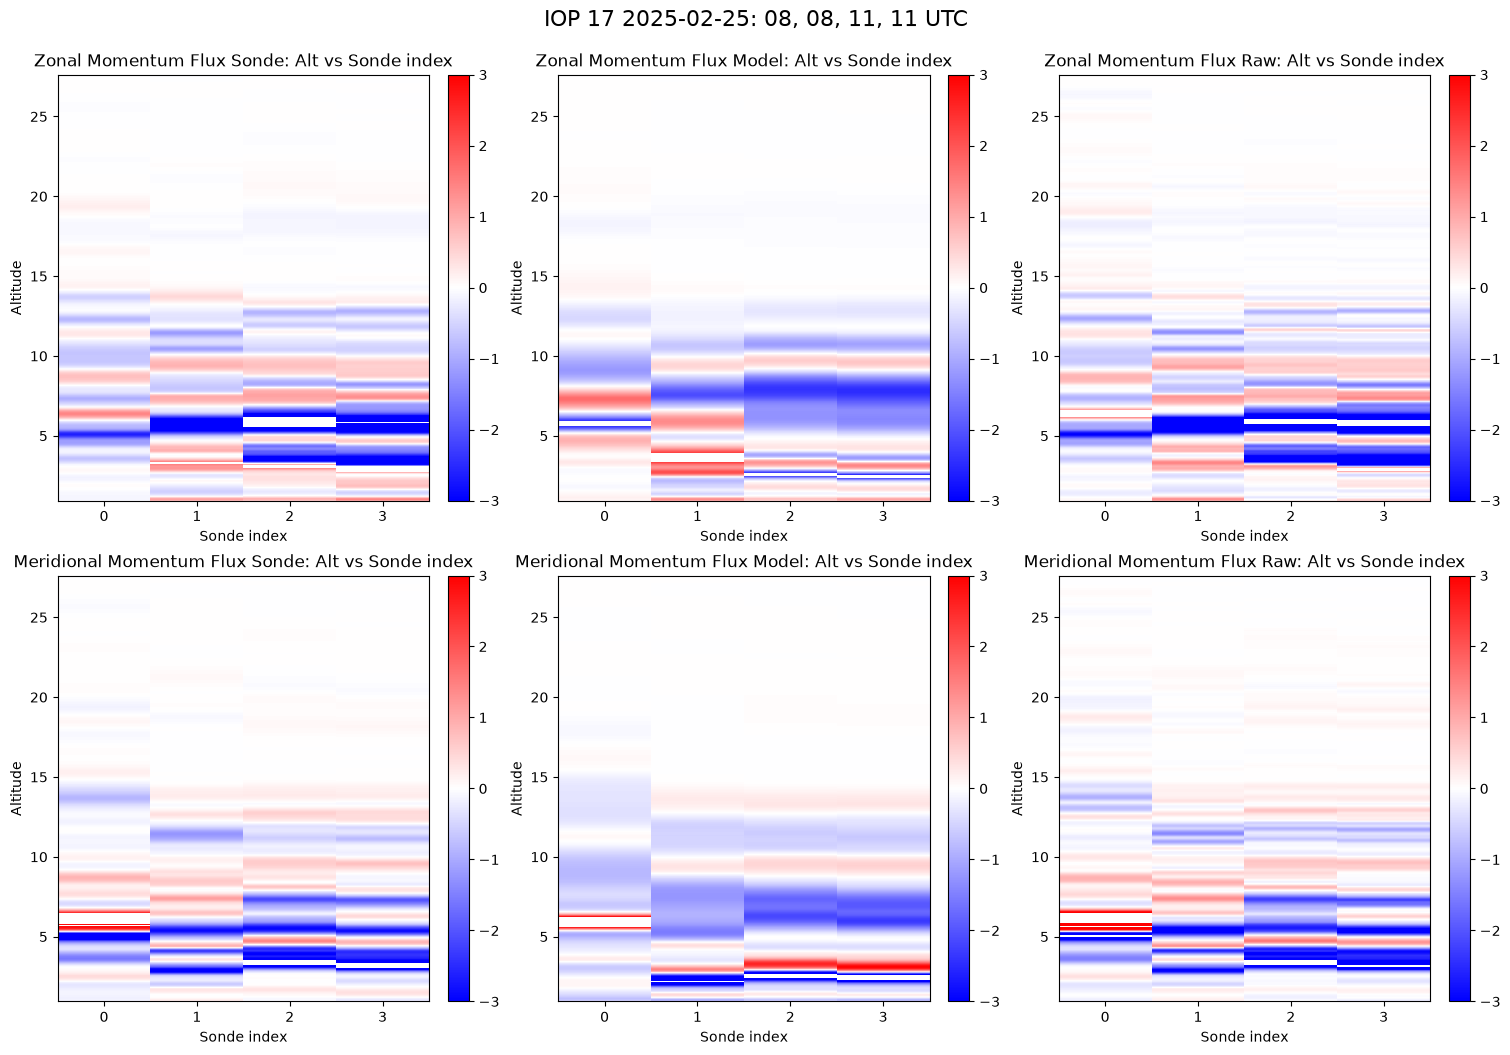

In [37]:
# Pcolormesh plot
# Now create the plot
fig = plt.figure(figsize=(15,10), layout="constrained")
ax = fig.subplots(2, 3).flatten()

# Centre the colorbar
norm = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
nlevs = 250
cmap = "bwr"

ylim = (None, None)
#ylim = (5,None)

u_s_plot = ax[0].pcolormesh(x, alts_y, Fluxes_u_s_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[0].set_title("Zonal Momentum Flux Sonde: Alt vs Sonde index")
ax[0].set_xlabel("Sonde index")
ax[0].set_xticks(x_axis[::])
ax[0].tick_params(axis="x", labelbottom=True)
ax[0].set_ylabel(f"Altitude")
ax[0].set_ylim(ylim)

u_m_plot = ax[1].pcolormesh(x, alts_y, Fluxes_u_m_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[1].set_title("Zonal Momentum Flux Model: Alt vs Sonde index")
ax[1].set_xlabel("Sonde index")
ax[1].set_xticks(x_axis[::])
ax[1].tick_params(axis="x", labelbottom=True)
ax[1].set_ylabel(f"Altitude")
ax[1].set_ylim(ylim)

u_r_plot = ax[2].pcolormesh(x, alts_y, Fluxes_u_r_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[2].set_title("Zonal Momentum Flux Raw: Alt vs Sonde index")
ax[2].set_xlabel("Sonde index")
ax[2].set_xticks(x_axis[::])
ax[2].tick_params(axis="x", labelbottom=True)
ax[2].set_ylabel(f"Altitude")
ax[2].set_ylim(ylim)

v_s_plot = ax[3].pcolormesh(x, alts_y, Fluxes_v_s_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[3].set_title("Meridional Momentum Flux Sonde: Alt vs Sonde index")
ax[3].set_xlabel("Sonde index")
ax[3].set_xticks(x_axis[::])
ax[3].tick_params(axis="x", labelbottom=True)
ax[3].set_ylabel(f"Altitude")
ax[3].set_ylim(ylim)

v_m_plot = ax[4].pcolormesh(x, alts_y, Fluxes_v_m_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[4].set_title("Meridional Momentum Flux Model: Alt vs Sonde index")
ax[4].set_xlabel("Sonde index")
ax[4].set_xticks(x_axis[::])
ax[4].tick_params(axis="x", labelbottom=True)
ax[4].set_ylabel(f"Altitude")
ax[4].set_ylim(ylim)

v_r_plot = ax[5].pcolormesh(x, alts_y, Fluxes_v_r_filtered, cmap=cmap, norm=norm)#, levels=nlevs)
ax[5].set_title("Meridional Momentum Flux Raw: Alt vs Sonde index")
ax[5].set_xlabel("Sonde index")
ax[5].set_xticks(x_axis[::])
ax[5].tick_params(axis="x", labelbottom=True)
ax[5].set_ylabel(f"Altitude")
ax[5].set_ylim(ylim)

fig.colorbar(u_s_plot, ax=ax[0])
fig.colorbar(v_s_plot, ax=ax[3])

fig.colorbar(u_m_plot, ax=ax[1])
fig.colorbar(v_m_plot, ax=ax[4])

fig.colorbar(u_r_plot, ax=ax[2])
fig.colorbar(v_r_plot, ax=ax[5])

fig.suptitle(f"IOP 17 2025-02-25: 08, 08, 11, 11 UTC", fontsize=16, y=1.04)

plt.savefig(f"Example_pcolormesh_plot_of_alt_vs_sonde.png")




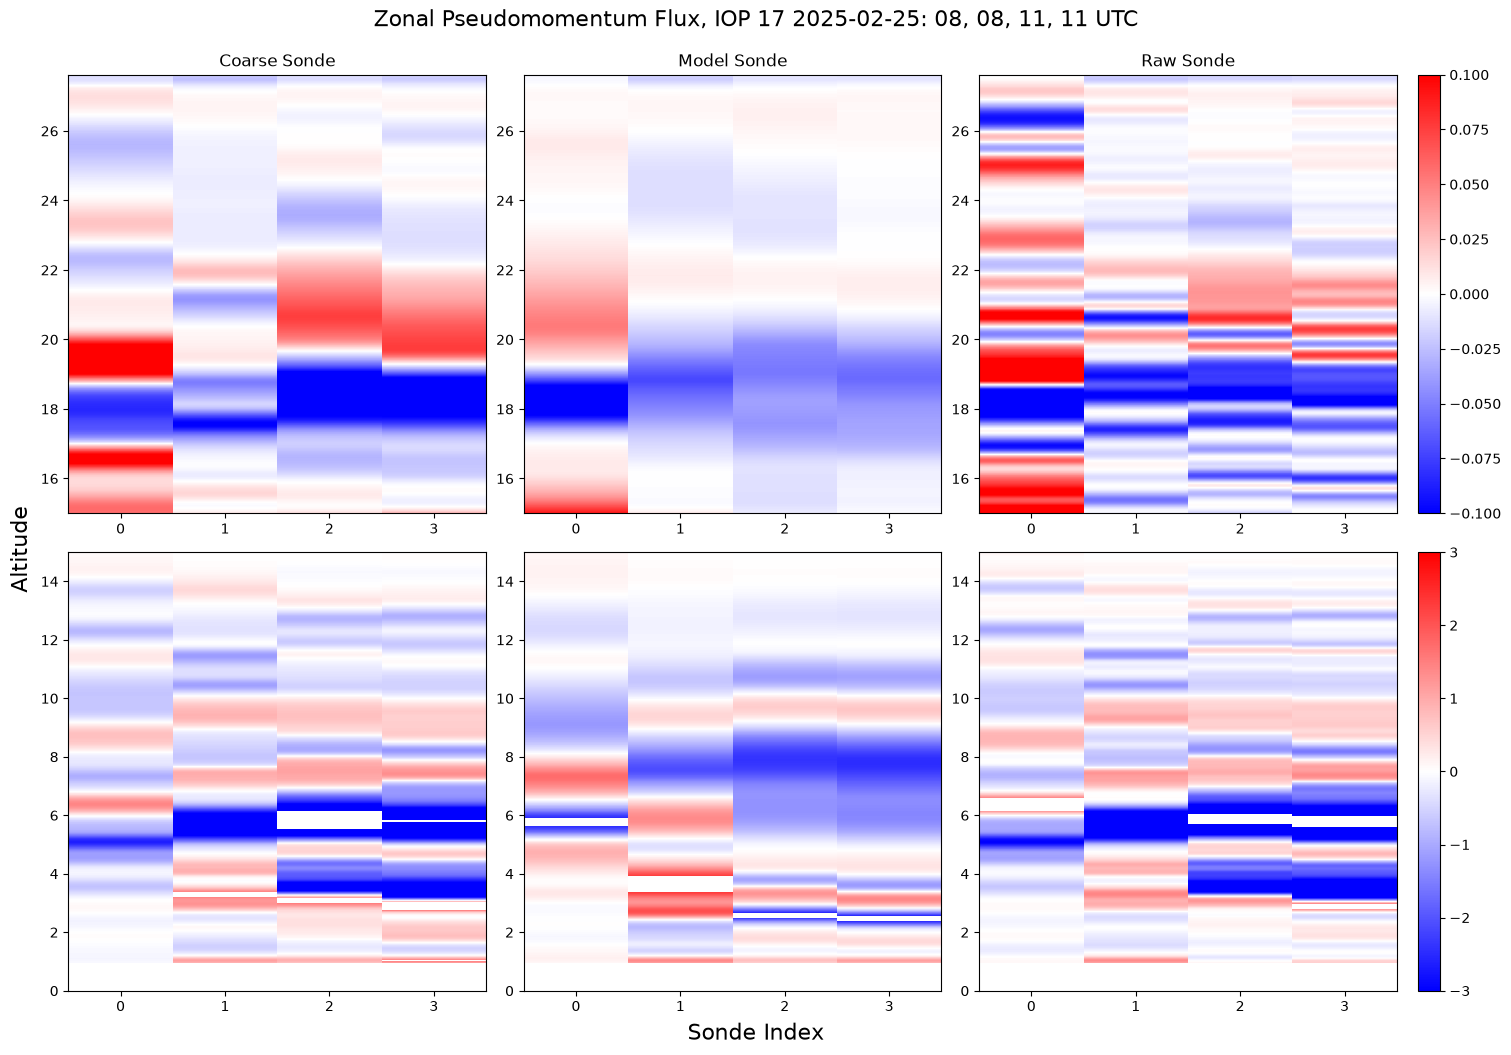

In [41]:
# Pcolormesh plot
# Now create the plot
fig = plt.figure(figsize=(15,10), layout="constrained")
ax = fig.subplots(2, 3).flatten()

# Centre the colorbar
norm_1 = TwoSlopeNorm(vmin=-0.1, vmax=0.1, vcenter=0)
norm_2 = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
nlevs = 250
cmap = "bwr"

ylim = (15, None)
ylim_2 = (0, 15)
#ylim = (5,None)

u_s_plot_1 = ax[0].pcolormesh(x, alts_y, Fluxes_u_s_filtered, cmap=cmap, norm=norm_1)#, levels=nlevs)
ax[0].set_title("Coarse Sonde")
#ax[0].set_xlabel("Sonde index")
ax[0].set_xticks(x_axis[::])
ax[0].tick_params(axis="x", labelbottom=True)
#ax[0].set_ylabel(f"Altitude")
ax[0].set_ylim(ylim)

u_m_plot_1 = ax[1].pcolormesh(x, alts_y, Fluxes_u_m_filtered, cmap=cmap, norm=norm_1)#, levels=nlevs)
ax[1].set_title("Model Sonde")
#ax[1].set_xlabel("Sonde index")
ax[1].set_xticks(x_axis[::])
ax[1].tick_params(axis="x", labelbottom=True)
#ax[1].set_ylabel(f"Altitude")
ax[1].set_ylim(ylim)

u_r_plot_1 = ax[2].pcolormesh(x, alts_y, Fluxes_u_r_filtered, cmap=cmap, norm=norm_1)#, levels=nlevs)
ax[2].set_title("Raw Sonde")
#ax[2].set_xlabel("Sonde index")
ax[2].set_xticks(x_axis[::])
ax[2].tick_params(axis="x", labelbottom=True)
#ax[2].set_ylabel(f"Altitude")
ax[2].set_ylim(ylim)

u_s_plot_2 = ax[3].pcolormesh(x, alts_y, Fluxes_u_s_filtered, cmap=cmap, norm=norm_2)#, levels=nlevs)
#ax[3].set_title("Meridional Momentum Flux Sonde: Alt vs Sonde index")
#ax[3].set_xlabel("Sonde index")
ax[3].set_xticks(x_axis[::])
ax[3].tick_params(axis="x", labelbottom=True)
#ax[3].set_ylabel(f"Altitude")
ax[3].set_ylim(ylim_2)

u_m_plot_2 = ax[4].pcolormesh(x, alts_y, Fluxes_u_m_filtered, cmap=cmap, norm=norm_2)#, levels=nlevs)
#ax[4].set_title("Meridional Momentum Flux Model: Alt vs Sonde index")
#ax[4].set_xlabel("Sonde index")
ax[4].set_xticks(x_axis[::])
ax[4].tick_params(axis="x", labelbottom=True)
#ax[4].set_ylabel(f"Altitude")
ax[4].set_ylim(ylim_2)

u_r_plot_2 = ax[5].pcolormesh(x, alts_y, Fluxes_u_r_filtered, cmap=cmap, norm=norm_2)#, levels=nlevs)
#ax[5].set_title("Meridional Momentum Flux Model: Alt vs Sonde index")
#ax[5].set_xlabel("Sonde index")
ax[5].set_xticks(x_axis[::])
ax[5].tick_params(axis="x", labelbottom=True)
#ax[5].set_ylabel(f"Altitude")
ax[5].set_ylim(ylim_2)

#fig.colorbar(u_s_plot_1, ax=ax[0])
#fig.colorbar(u_m_plot_1, ax=ax[1])
fig.colorbar(u_r_plot_1, ax=ax[2])
#fig.colorbar(u_s_plot_2, ax=ax[3])
#fig.colorbar(u_m_plot_2, ax=ax[4])
fig.colorbar(u_r_plot_2, ax=ax[5])

fig.suptitle(f"Zonal Pseudomomentum Flux, IOP 17 2025-02-25: 08, 08, 11, 11 UTC", fontsize=16, y=1.04)
fig.supxlabel(f"Sonde Index", fontsize=16)
fig.supylabel(f"Altitude", fontsize=16)

plt.savefig(f"Zonal_momentum_sonde_vs_model_iop17.png")




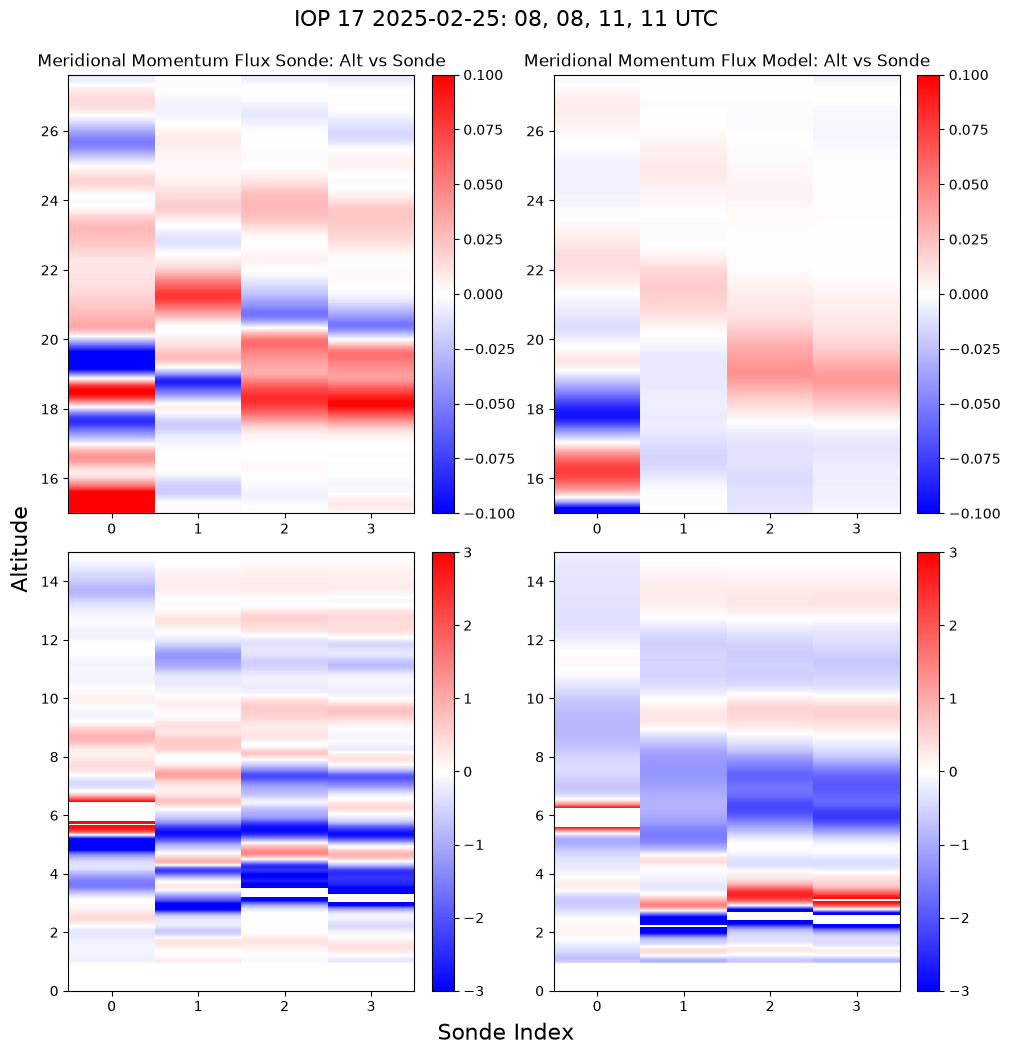

In [ ]:
# Pcolormesh plot
# Now create the plot
fig = plt.figure(figsize=(10,10), layout="constrained")
ax = fig.subplots(2, 2).flatten()

# Centre the colorbar
norm_1 = TwoSlopeNorm(vmin=-0.1, vmax=0.1, vcenter=0)
norm_2 = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
nlevs = 250
cmap = "bwr"

ylim = (15, None)
ylim_2 = (0, 15)
#ylim = (5,None)

v_s_plot_1 = ax[0].pcolormesh(x, alts_y, Fluxes_v_s_filtered, cmap=cmap, norm=norm_1)#, levels=nlevs)
ax[0].set_title("Meridional Momentum Flux Sonde: Alt vs Sonde")
#ax[0].set_xlabel("Sonde index")
ax[0].set_xticks(x_axis[::])
ax[0].tick_params(axis="x", labelbottom=True)
#ax[0].set_ylabel(f"Altitude")
ax[0].set_ylim(ylim)

v_m_plot_1 = ax[1].pcolormesh(x, alts_y, Fluxes_v_m_filtered, cmap=cmap, norm=norm_1)#, levels=nlevs)
ax[1].set_title("Meridional Momentum Flux Model: Alt vs Sonde")
#ax[1].set_xlabel("Sonde index")
ax[1].set_xticks(x_axis[::])
ax[1].tick_params(axis="x", labelbottom=True)
#ax[1].set_ylabel(f"Altitude")
ax[1].set_ylim(ylim)

v_s_plot_2 = ax[2].pcolormesh(x, alts_y, Fluxes_v_s_filtered, cmap=cmap, norm=norm_2)#, levels=nlevs)
#ax[2].set_title("Meridional Momentum Flux Sonde: Alt vs Sonde index")
#ax[2].set_xlabel("Sonde index")
ax[2].set_xticks(x_axis[::])
ax[2].tick_params(axis="x", labelbottom=True)
#ax[2].set_ylabel(f"Altitude")
ax[2].set_ylim(ylim_2)

v_m_plot_2 = ax[3].pcolormesh(x, alts_y, Fluxes_v_m_filtered, cmap=cmap, norm=norm_2)#, levels=nlevs)
#ax[3].set_title("Meridional Momentum Flux Model: Alt vs Sonde index")
#ax[3].set_xlabel("Sonde index")
ax[3].set_xticks(x_axis[::])
ax[3].tick_params(axis="x", labelbottom=True)
#ax[3].set_ylabel(f"Altitude")
ax[3].set_ylim(ylim_2)

fig.colorbar(v_s_plot_1, ax=ax[0])
fig.colorbar(v_m_plot_1, ax=ax[1])
fig.colorbar(v_s_plot_2, ax=ax[2])
fig.colorbar(v_m_plot_2, ax=ax[3])

fig.suptitle(f"IOP 17 2025-02-25: 08, 08, 11, 11 UTC", fontsize=16, y=1.04)
fig.supxlabel(f"Sonde Index", fontsize=16)
fig.supylabel(f"Altitude", fontsize=16)

plt.savefig(f"Meridional_momentum_sonde_vs_model_iop17.png")



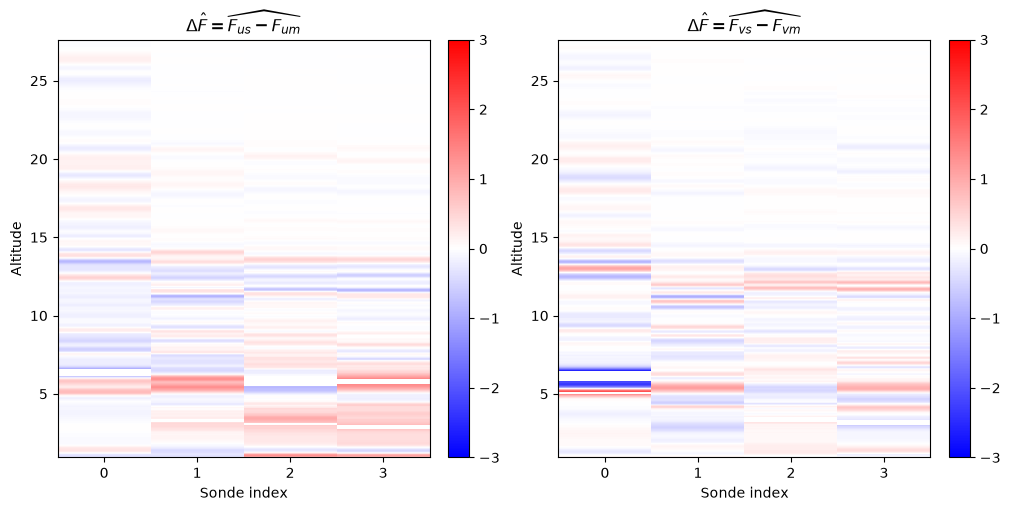

In [40]:
# Now a difference plot

# First find the differences at points where sonde is not nan
nan_mask_u_s = np.isnan(Fluxes_u_s_filtered)
nan_mask_v_s = np.isnan(Fluxes_v_s_filtered)

Fluxes_u_m_yesnans = Fluxes_u_r_filtered.copy()
Fluxes_v_m_yesnans = Fluxes_v_r_filtered.copy()

Fluxes_u_m_yesnans[nan_mask_u_s] = np.nan
Fluxes_v_m_yesnans[nan_mask_v_s] = np.nan

Flux_u_diff = Fluxes_u_s_filtered - Fluxes_u_m_yesnans
Flux_v_diff = Fluxes_v_s_filtered - Fluxes_v_m_yesnans


scale_u = np.sqrt(np.nanmean((Fluxes_u_s_filtered**2 + Fluxes_u_m_filtered**2) / 2, axis=1))
Flux_u_diff_norm = Flux_u_diff/(scale_u[:, None])

scale_v = np.sqrt(np.nanmean((Fluxes_v_s_filtered**2 + Fluxes_v_m_filtered**2) / 2, axis=1))
Flux_v_diff_norm = Flux_v_diff/(scale_v[:, None])

# Contourf Plot
# Now create the plot
fig = plt.figure(figsize=(10,5), layout="constrained")
ax = fig.subplots(1, 2).flatten()

# Centre the colorbar

norm = TwoSlopeNorm(vmin=-3, vmax=3, vcenter=0)
ylim = (None, None)

#norm = TwoSlopeNorm(vmin=-0.1, vmax=0.1, vcenter=0)
#ylim = (15,None)

nlevs = 250
cmap = "bwr"


u_s_plot = ax[0].pcolormesh(x, alts_y, Flux_u_diff_norm, cmap=cmap, norm=norm)#, levels=nlevs)
ax[0].set_title(r"$\Delta \hat{F} = \widehat{F_{us} - F_{um}}$")
ax[0].set_xlabel("Sonde index")
ax[0].set_xticks(x_axis[::])
ax[0].tick_params(axis="x", labelbottom=True)
ax[0].set_ylabel(f"Altitude")
ax[0].set_ylim(ylim)

v_s_plot = ax[1].pcolormesh(x, alts_y, Flux_v_diff_norm, cmap=cmap, norm=norm)#, levels=nlevs)
ax[1].set_title(r"$\Delta \hat{F} = \widehat{F_{vs} - F_{vm}}$")
ax[1].set_xlabel("Sonde index")
ax[1].set_xticks(x_axis[::])
ax[1].tick_params(axis="x", labelbottom=True)
ax[1].set_ylabel(f"Altitude")
ax[1].set_ylim(ylim)

fig.colorbar(u_s_plot, ax=ax[0])
fig.colorbar(v_s_plot, ax=ax[1])


plt.savefig("example_plot_of_flux_difference_for_four_sondes.png")